# 07 — Bônus: Transformers com patches (PatchTST)

**Trabalho final — Tópicos Especiais em ESSC II (IA aplicada a Séries Temporais)**

O enunciado (item 2.3-E) permite acrescentar uma arquitetura avançada do survey de DTSF (Kong et al., 2025), com duas exigências: **justificar teoricamente a escolha** e **analisar se o ganho compensa a complexidade e o custo computacional**.

### Por que o PatchTST

O **PatchTST** (Nie et al., ICLR 2023) é um dos modelos do survey que melhor se encaixam no nosso problema, por três razões:

1. **Patches:** a série é cortada em blocos de instantes consecutivos (aqui, 8 blocos de 4 instantes, ~0,4 s cada), e cada bloco vira um *token*. A atenção passa a comparar **trechos de movimento**, e não instantes isolados, e o custo da atenção cai de $O(T^2)$ para $O((T/P)^2)$.
2. **Independência de canais (*channel independence*):** cada um dos 321 canais é processado separadamente pelo **mesmo** Transformer, com pesos compartilhados. Isso funciona como regularização: o modelo vê 321 × ~670 séries univariadas no treino, em vez de ~670 séries multivariadas, o que é importante com poucos vídeos.
3. **Atenção global:** cada trecho pode olhar para todos os outros. É o oposto da GRU, que decide pelo último estado e sofria com a fase de retração do gesto (notebook 05).

O contraponto: com independência de canais, o modelo **não vê a relação entre canais** (por exemplo, a mão em relação ao rosto) até a camada final. Por isso comparamos também um **Transformer de patches multicanal**, em que cada *token* é um bloco de 4 instantes com **todos** os 321 canais (o mesmo princípio dos *Vision Transformers*).

### Desenho do experimento

| Modelo | *Tokens* | Mistura de canais |
|---|---|---|
| **CNN-1D** (referência, melhor modelo do trabalho) | — | sim, desde a 1ª camada |
| **PatchTST** (canais independentes) | 8 patches × 321 canais, cada canal separado | só na camada de saída |
| **Transformer de patches multicanal** | 8 patches, cada um com 4 × 321 valores | sim, no próprio *token* |

Mesmo protocolo de todo o trabalho: as 4 rodadas por sinalizante, 3 sementes, *early stopping* na validação, sinal bruto. A CNN-1D é treinada de novo **nesta mesma máquina** para a comparação pareada (teste de Wilcoxon) e para medir os custos nas mesmas condições.

**Tempo com GPU:** ~45 min. O notebook grava cada treino e continua de onde parou.

## 1. Configuração

In [1]:
import os, sys, time
from pathlib import Path
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

SEMENTES = [0, 1, 2]
RODADAS = [0, 1, 2, 3]
MAX_EPOCAS, PACIENCIA, LOTE = 200, 25, 32
P = 4                                   # tamanho do patch (instantes por token)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("TensorFlow", tf.__version__, "| GPU:", [g.name for g in tf.config.list_physical_devices("GPU")] or "nenhuma (CPU)")

IN_COLAB = "google.colab" in sys.modules
DRIVE_OK = False
if IN_COLAB:
    from google.colab import drive
    try:
        drive.mount("/content/drive", force_remount=True)
        BASE = Path("/content/drive/MyDrive/trabalho_series_temporais")
        DRIVE_OK = True
    except Exception as e:
        print("AVISO: não consegui montar o Google Drive:", e)
        BASE = Path("/content/trabalho_series_temporais")
else:
    BASE = Path.cwd().parent if (Path.cwd().parent / "dados").exists() else Path.cwd()
DADOS, FIG, RES = BASE / "dados", BASE / "figuras", BASE / "resultados"
HIST = RES / "07_historicos"
for p in (DADOS, FIG, RES, HIST):
    p.mkdir(parents=True, exist_ok=True)
if not (DADOS / "minds_st.npz").exists():
    if IN_COLAB:
        from google.colab import files
        print("Envie o arquivo minds_st.npz (selecione SÓ ele):")
        enviados = files.upload()
        nome = next(n for n in enviados if n.startswith("minds_st"))
        (DADOS / "minds_st.npz").write_bytes(enviados[nome])
    else:
        raise FileNotFoundError(f"Não achei {DADOS / 'minds_st.npz'} (rode o notebook 00).")
ARQ = RES / "07_bonus_por_rodada.csv"

def salvar_fig(nome):
    plt.savefig(FIG / f"07_{nome}.png", bbox_inches="tight", dpi=150)

d = np.load(DADOS / "minds_st.npz", allow_pickle=False)
X, y = d["X"], d["y"]
classes = d["classes"].astype(str)
sinalizante, grupo, VAL = d["sinalizante"], d["grupo"], d["validacao"]
N, T, F = X.shape
K = len(classes)
assert T % P == 0, "T precisa ser múltiplo do tamanho do patch"
NP = T // P                              # número de patches por série

def particao(rodada):
    te = np.where(grupo == rodada)[0]
    va = np.where(np.isin(sinalizante, VAL[rodada]))[0]
    tr = np.setdiff1d(np.arange(N), np.concatenate([te, va]))
    return tr, va, te

def padronizar(X, tr):
    mu = X[tr].reshape(-1, X.shape[-1]).mean(0)
    sd = X[tr].reshape(-1, X.shape[-1]).std(0) + 1e-6
    return ((X - mu) / sd).astype(np.float32)

def metricas(y_true, y_pred):
    return dict(acuracia=accuracy_score(y_true, y_pred), acuracia_balanceada=balanced_accuracy_score(y_true, y_pred),
                f1_macro=f1_score(y_true, y_pred, average="macro"))
print(f"séries {N} | T={T} | F={F} | {NP} patches de {P} instantes")

I0000 00:00:1795537057.847720     467 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795537060.952291     467 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | GPU: ['/physical_device:GPU:0']


séries 1158 | T=32 | F=321 | 8 patches de 4 instantes


## 2. Os modelos

**Bloco Transformer** (encoder *pre-norm*, como no PatchTST): normalização → atenção multi-cabeça (4 cabeças) → soma residual → normalização → rede *feed-forward* (2 camadas) → soma residual. São 2 blocos, com dimensão $d = 64$ e *dropout* 0,1. Uma **posição aprendida** é somada a cada patch, porque a atenção, sozinha, não sabe a ordem dos *tokens*.

- **PatchTST:** (lote, 32, 321) → (lote × 321, 8 patches, 4 valores) → projeção linear para $d$ → 2 blocos → média dos 8 *tokens* → (lote, 321 × 64) → *dropout* → saída com 20 classes.
- **Transformer multicanal:** (lote, 32, 321) → (lote, 8 patches, 4 × 321 valores) → projeção linear para $d$ → 2 blocos → média dos *tokens* → saída.
- **CNN-1D:** a mesma dos notebooks 03 a 06.

In [2]:
class PosicaoAprendida(layers.Layer):
    # soma um vetor aprendido a cada posição (patch) da sequência
    def __init__(self, n_pos, dim, **kw):
        super().__init__(**kw)
        self.n_pos, self.dim = n_pos, dim
    def build(self, _):
        self.pos = self.add_weight(name="pos", shape=(self.n_pos, self.dim), initializer="random_normal")
    def call(self, x):
        return x + self.pos

def bloco_transformer(h, d=64, cabecas=4, ff=128, drop=0.1):
    a = layers.LayerNormalization(epsilon=1e-6)(h)
    a = layers.MultiHeadAttention(num_heads=cabecas, key_dim=d // cabecas, dropout=drop)(a, a)
    h = layers.Add()([h, layers.Dropout(drop)(a)])
    f = layers.LayerNormalization(epsilon=1e-6)(h)
    f = layers.Dense(ff, activation="gelu")(f)
    f = layers.Dense(d)(layers.Dropout(drop)(f))
    return layers.Add()([h, layers.Dropout(drop)(f)])

def patchtst(d=64, blocos=2):
    x_in = keras.Input(shape=(T, F))
    h = layers.GaussianNoise(0.1)(x_in)
    h = layers.Permute((2, 1))(h)                                  # (lote, F, T)
    h = layers.Lambda(lambda z: tf.reshape(z, (-1, NP, P)))(h)     # (lote*F, NP, P): cada canal vira uma série de patches
    h = PosicaoAprendida(NP, d)(layers.Dense(d)(h))
    for _ in range(blocos):
        h = bloco_transformer(h, d)
    h = layers.GlobalAveragePooling1D()(layers.LayerNormalization(epsilon=1e-6)(h))   # (lote*F, d)
    h = layers.Lambda(lambda z: tf.reshape(z, (-1, F * d)))(h)    # volta a juntar os canais: (lote, F*d)
    out = layers.Dense(K, activation="softmax")(layers.Dropout(0.3)(h))
    return keras.Model(x_in, out, name="PatchTST")

def transformer_multicanal(d=64, blocos=2):
    x_in = keras.Input(shape=(T, F))
    h = layers.GaussianNoise(0.1)(x_in)
    h = layers.Reshape((NP, P * F))(h)                             # cada token = 4 instantes × 321 canais
    h = PosicaoAprendida(NP, d)(layers.Dense(d)(h))
    for _ in range(blocos):
        h = bloco_transformer(h, d)
    h = layers.GlobalAveragePooling1D()(layers.LayerNormalization(epsilon=1e-6)(h))
    out = layers.Dense(K, activation="softmax")(layers.Dropout(0.3)(h))
    return keras.Model(x_in, out, name="Transformer_multicanal")

def cnn1d():
    x_in = keras.Input(shape=(T, F))
    h = layers.GaussianNoise(0.1)(x_in)
    for filtros, k in [(64, 5), (128, 5), (128, 3)]:
        h = layers.Activation("relu")(layers.BatchNormalization()(layers.Conv1D(filtros, k, padding="same")(h)))
    out = layers.Dense(K, activation="softmax")(layers.Dropout(0.3)(layers.GlobalAveragePooling1D()(h)))
    return keras.Model(x_in, out, name="CNN-1D")

MODELOS = {"CNN-1D": cnn1d, "PatchTST": patchtst, "Transformer multicanal": transformer_multicanal}
PARAM = {}
for nome, f in MODELOS.items():
    PARAM[nome] = f().count_params()
    keras.backend.clear_session()
display(pd.Series(PARAM, name="parâmetros").map("{:,}".format).to_frame())

# conferência do recorte em patches: o patch j do canal c deve ser X[t = 4j..4j+3, c]
_z = tf.reshape(tf.transpose(tf.constant(X[:2]), (0, 2, 1)), (-1, NP, P)).numpy()   # a mesma operação do modelo
assert np.allclose(_z[0 * F + 1][2], X[0, 8:12, 1]) and np.allclose(_z[1 * F + 5][0], X[1, 0:4, 5]), "recorte incorreto"
print("recorte em patches conferido")
keras.backend.clear_session()

,parâmetros
CNN-1D,"197,012"
PatchTST,"478,804"
Transformer multicanal,"151,124"


recorte em patches conferido


## 3. Treino

Adam com taxa 5×10⁻⁴ para os Transformers (mais sensíveis a passos grandes) e 10⁻³ para a CNN-1D, como no notebook 03. Perda de entropia cruzada, *early stopping* pela perda de validação (paciência 25) e redução da taxa pela metade quando a validação estaciona.

In [3]:
res = pd.read_csv(ARQ) if ARQ.exists() else pd.DataFrame(columns=["modelo", "rodada", "semente"])
feitos = set(zip(res.modelo, res.rodada, res.semente))
TAXA = {"CNN-1D": 1e-3, "PatchTST": 5e-4, "Transformer multicanal": 5e-4}
for k in RODADAS:
    tr, va, te = particao(k)
    Z = padronizar(X, tr)
    for nome, construtor in MODELOS.items():
        for s in SEMENTES:
            if (nome, k, s) in feitos:
                continue
            keras.utils.set_random_seed(s)
            m = construtor()
            m.compile(optimizer=keras.optimizers.Adam(TAXA[nome]), loss="sparse_categorical_crossentropy",
                      metrics=["accuracy"], jit_compile=False)
            cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=PACIENCIA, restore_best_weights=True),
                  keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=10, min_lr=1e-5)]
            t_ini = time.time()
            h = m.fit(Z[tr], y[tr], validation_data=(Z[va], y[va]), epochs=MAX_EPOCAS, batch_size=LOTE, callbacks=cb, verbose=0)
            t_treino = time.time() - t_ini
            t0 = time.time(); pred = m.predict(Z[te], verbose=0).argmax(1); t_inf = (time.time() - t0) / len(te) * 1000
            epocas = len(h.history["loss"])
            linha = dict(modelo=nome, rodada=k, semente=s, parametros=m.count_params(), epocas=epocas,
                         melhor_epoca=int(np.argmin(h.history["val_loss"])) + 1, tempo_s=t_treino,
                         s_por_epoca=t_treino / epocas, ms_por_video=t_inf, **metricas(y[te], pred))
            pd.DataFrame(h.history).to_csv(HIST / f"{nome.replace(' ', '_')}_r{k}_s{s}.csv", index_label="epoca")
            res = pd.concat([res, pd.DataFrame([linha])], ignore_index=True)
            res.to_csv(ARQ, index=False)
            print(f"rodada {k} | {nome:22s} | semente {s} | F1 teste {linha['f1_macro']:.3f} | {epocas} épocas "
                  f"| {t_treino:.0f}s", flush=True)
            keras.backend.clear_session()
print("treinos:", len(pd.read_csv(ARQ)))

rodada 0 | CNN-1D                 | semente 0 | F1 teste 0.911 | 84 épocas | 43s


rodada 0 | CNN-1D                 | semente 1 | F1 teste 0.869 | 78 épocas | 34s


rodada 0 | CNN-1D                 | semente 2 | F1 teste 0.893 | 63 épocas | 27s


rodada 0 | PatchTST               | semente 0 | F1 teste 0.761 | 61 épocas | 284s


rodada 0 | PatchTST               | semente 1 | F1 teste 0.811 | 68 épocas | 362s


rodada 0 | PatchTST               | semente 2 | F1 teste 0.655 | 28 épocas | 139s


... (27 outputs left out)

rodada 3 | Transformer multicanal | semente 0 | F1 teste 0.942 | 94 épocas | 88s


rodada 3 | Transformer multicanal | semente 1 | F1 teste 0.924 | 59 épocas | 57s


rodada 3 | Transformer multicanal | semente 2 | F1 teste 0.923 | 76 épocas | 68s


treinos: 36


## 4. Ganho × custo

F1 macro no teste (média ± desvio de 4 rodadas × 3 sementes), diferença pareada em relação à CNN-1D (mesma rodada e semente, teste de Wilcoxon) e o custo: parâmetros, tempo de treino, tempo por época e tempo de inferência por vídeo.

,F1 macro (%),acurácia (%),parâmetros,treino (s),s/época,inferência (ms/vídeo),melhor época,Δ vs CNN-1D (p.p.),p (Wilcoxon)
modelo,,,,,,,,,
CNN-1D,90.8 ± 2.0,91.5,"197,012",39,0.49,1.16,55,—,—
PatchTST,79.0 ± 8.3,80.3,"478,804",376,5.95,3.24,36,-11.8,0.000
Transformer multicanal,90.4 ± 1.9,91.2,"151,124",70,0.96,1.77,49,-0.4,0.622


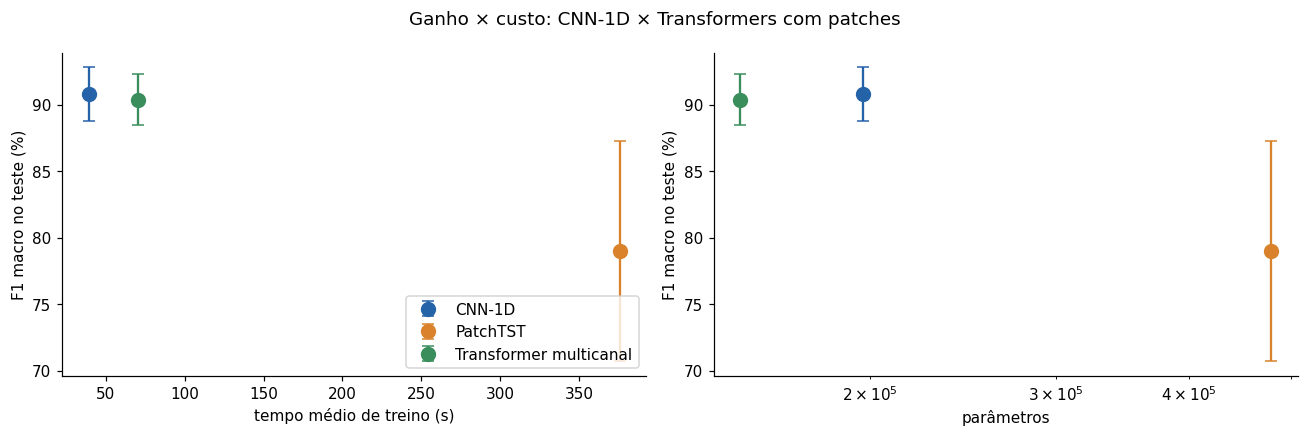

In [4]:
res = pd.read_csv(ARQ)
base = res[res.modelo == "CNN-1D"].set_index(["rodada", "semente"]).f1_macro
linhas = []
for nome in MODELOS:
    r = res[res.modelo == nome]
    v = r.set_index(["rodada", "semente"]).f1_macro
    linha = {"modelo": nome, "F1 macro (%)": f"{100 * v.mean():.1f} ± {100 * v.std():.1f}",
             "acurácia (%)": f"{100 * r.acuracia.mean():.1f}", "parâmetros": f"{int(r.parametros.iloc[0]):,}",
             "treino (s)": f"{r.tempo_s.mean():.0f}", "s/época": f"{r.s_por_epoca.mean():.2f}",
             "inferência (ms/vídeo)": f"{r.ms_por_video.mean():.2f}", "melhor época": f"{r.melhor_epoca.mean():.0f}"}
    if nome != "CNN-1D":
        delta = (v - base.reindex(v.index)).dropna()
        p = wilcoxon(delta).pvalue if len(delta) >= 6 and np.any(delta != 0) else np.nan
        linha.update({"Δ vs CNN-1D (p.p.)": f"{100 * delta.mean():+.1f}", "p (Wilcoxon)": f"{p:.3f}"})
    linhas.append(linha)
tab = pd.DataFrame(linhas).set_index("modelo").fillna("—")
display(tab)
tab.to_csv(RES / "07_tabela_bonus.csv")

g = res.groupby("modelo").agg(f1=("f1_macro", "mean"), dp=("f1_macro", "std"), treino=("tempo_s", "mean"),
                              param=("parametros", "first")).reindex(list(MODELOS))
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
cores = ["#2563A8", "#D9822B", "#3A8E5C"]
for ax, col, rot in [(axs[0], "treino", "tempo médio de treino (s)"), (axs[1], "param", "parâmetros")]:
    for (nome, row), cor in zip(g.iterrows(), cores):
        ax.errorbar(row[col], 100 * row.f1, yerr=100 * row.dp, fmt="o", ms=9, color=cor, capsize=4, label=nome)
    ax.set_xlabel(rot); ax.set_ylabel("F1 macro no teste (%)")
axs[1].set_xscale("log"); axs[0].legend(loc="lower right")
fig.suptitle("Ganho × custo: CNN-1D × Transformers com patches")
plt.tight_layout(); salvar_fig("ganho_custo"); plt.show()

## 5. Curvas de aprendizado (rodada 0, semente 0)

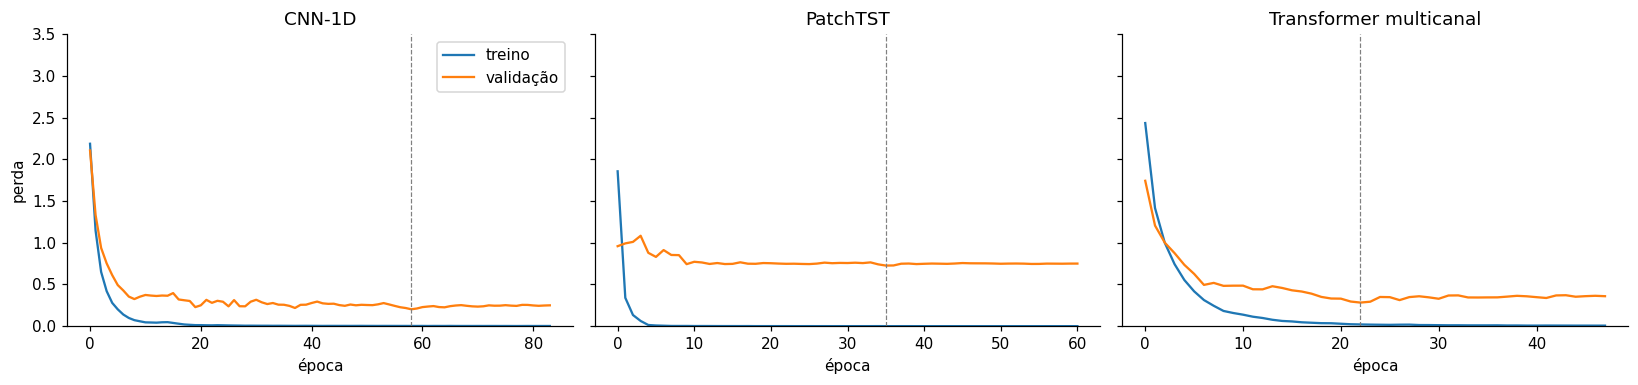

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, nome in zip(axs, MODELOS):
    arq = HIST / f"{nome.replace(' ', '_')}_r0_s0.csv"
    if not arq.exists():
        continue
    h = pd.read_csv(arq)
    ax.plot(h.loss, label="treino"); ax.plot(h.val_loss, label="validação")
    ax.axvline(h.val_loss.idxmin(), ls="--", color="gray", lw=.8)
    ax.set_title(nome); ax.set_xlabel("época")
axs[0].set_ylabel("perda"); axs[0].set_ylim(0, 3.5); axs[0].legend()
plt.tight_layout(); salvar_fig("curvas_aprendizado"); plt.show()

## 6. Síntese

| Modelo | F1 macro (%) | Δ vs CNN-1D | Parâmetros | Treino (s) | s/época | Inferência (ms/vídeo) |
|---|---|---|---|---|---|---|
| CNN-1D (referência) | **90,8 ± 2,0** | — | 197 mil | 39 | 0,49 | 1,2 |
| Transformer de patches multicanal | 90,4 ± 1,9 | −0,4 (p = 0,62) | **151 mil** | 70 | 0,96 | 1,8 |
| PatchTST (canais independentes) | 79,0 ± 8,3 | **−11,8 (p < 0,001)** | 479 mil | 376 | 5,95 | 3,2 |

*4 rodadas × 3 sementes, sinalizantes nunca vistos; Δ pareado (mesma rodada e semente) com teste de Wilcoxon; tempos na RTX 3060 (WSL2).*

**1. Nenhum Transformer supera a CNN-1D.** O Transformer multicanal **empata** com ela (−0,4 ponto, sem significância; ganha na rodada 3 e perde nas outras), com 23% menos parâmetros. O PatchTST fica 11,8 pontos abaixo, com o maior desvio de todos os modelos de rede do trabalho depois da SimpleRNN (±8,3).

**2. A independência de canais é a hipótese errada para este problema.** O PatchTST foi pensado para previsão de séries em que cada canal tem uma dinâmica própria (vários sensores, várias lojas), e tratar os canais separadamente funciona como regularização. Num sinal de Libras, o significado está justamente na **relação entre canais**: a configuração da mão só tem sentido junto com a locação (a mão perto do rosto ou do peito) e com o movimento do braço. No PatchTST, essa relação só aparece na camada final, uma camada linear sobre 321 × 64 valores (411 mil dos 479 mil parâmetros). As curvas de aprendizado mostram a consequência: a perda de treino chega a zero em 4 épocas, enquanto a de validação estaciona em ~0,75 (contra ~0,25 da CNN-1D). O modelo **decora** os vídeos do treino pela camada de saída, em vez de aprender padrões que valham para pessoas novas.

**3. Misturar os canais no *token* resolve.** No Transformer multicanal, cada patch de 4 instantes carrega os 321 canais juntos, e a atenção compara trechos completos do gesto. Esse modelo chega ao nível da CNN-1D, o que confirma que o problema do PatchTST é a independência de canais, e não a atenção ou os patches.

**4. O ganho não compensa o custo** (exigência do item 2.3-E). O Transformer multicanal tem o mesmo desempenho da CNN-1D, mas leva ~2× mais tempo de treino por época e ~1,5× mais tempo de inferência. O PatchTST custa ~10× mais tempo de treino e ~3× mais tempo de inferência para entregar um resultado pior. Com ~670 vídeos de treino e séries de só 32 instantes, a vantagem teórica da atenção (relações de longo alcance) não tem onde aparecer: a CNN-1D, com campo receptivo e média global, já enxerga o gesto inteiro. É o mesmo diagnóstico do resto do trabalho: o limite é a variação entre sinalizantes, e não a capacidade do modelo.


In [6]:
if IN_COLAB and not DRIVE_OK:
    import shutil
    from google.colab import files
    shutil.make_archive("/content/resultados_07", "zip", str(BASE), "resultados")
    files.download("/content/resultados_07.zip")
else:
    print("resultados gravados em", RES)

resultados gravados em /mnt/d/ProjetoMestrado/trabalho_series_temporais/resultados
